In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler 

In [2]:
df = pd.read_csv("Mall_Customers.csv")
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)
print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


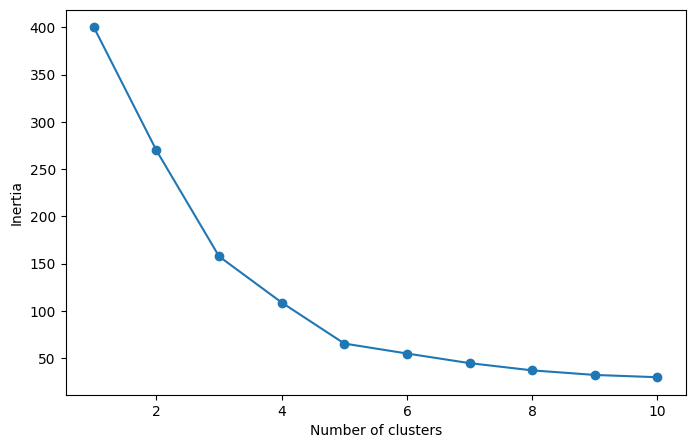

In [3]:
#Elbow Method 
from sklearn.cluster import KMeans
inertias = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scale)
    inertias.append(kmeans.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

In [4]:
#Silhouette Score
from sklearn.metrics import silhouette_score
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scale)
    score = silhouette_score(X_scale, labels)
    print(f"i = {i}, Silhouette Score = {score:.3f}")

i = 2, Silhouette Score = 0.321
i = 3, Silhouette Score = 0.467
i = 4, Silhouette Score = 0.494
i = 5, Silhouette Score = 0.555
i = 6, Silhouette Score = 0.540
i = 7, Silhouette Score = 0.528
i = 8, Silhouette Score = 0.455
i = 9, Silhouette Score = 0.457
i = 10, Silhouette Score = 0.443


In [5]:
#Applying K-Means clustering
i = 5
kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scale)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


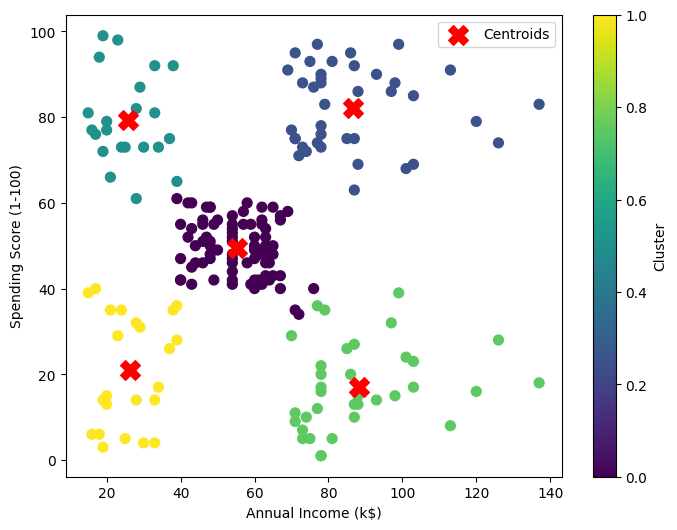

In [8]:
#Visualize K-Means cluster
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.figure(figsize=(8, 6))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], c=df["Cluster"], cmap="viridis", s=50)
plt.scatter(centroids[:, 0], centroids[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.colorbar(label="Cluster")
plt.show()

In [9]:
#Calculating silhoutte score
score = silhouette_score(X_scale, df["Cluster"])
print("Number of clusters: ", i)
print("Silhouette score: ", round(score, 3))

Number of clusters:  5
Silhouette score:  0.555


In [13]:
#Analyzing customer clusters/segments 
cluster_sum = df.groupby("Cluster")[["Annual Income (k$)", "Spending Score (1-100)"]].mean()
print("Mean: \n", cluster_sum.round(2))
cluster_num = df["Cluster"].value_counts().sort_index()
print("Number of Customers per cluster: \n", cluster_num)

Mean: 
          Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91
Number of Customers per cluster: 
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [14]:
#Saving the results 
df.to_csv("kmeans_exp1_result.csv", index=False)
print("K-Means Experiment 1 results saved successfully!")

K-Means Experiment 1 results saved successfully!
